# Onde abrir o próximo ponto de distribuição

**Pergunta do time:** *se a LH Nautical fosse abrir mais um centro de distribuição — loja ou armazém — em qual estado ele deveria ficar?*

**Por que isso importa para a LH Nautical:** hoje as 6 unidades (3 armazéns e 3 lojas, em apenas 4 estados: PR, AP, PI e AL) atendem clientes nas 27 UFs. Frete e prazo dependem de quantos quilômetros o pedido percorre, então saber *onde falta ponto* é saber onde cada pedido fica mais caro e mais lento do que precisava.

**Resposta curta:**

1. **Antes de abrir qualquer ponto, o maior ganho está em despachar pela unidade certa.** Nos últimos 12 meses só **26,4%** das unidades vendidas saíram da unidade mais próxima do cliente. A distância média real foi de **1.657 km**; se cada pedido saísse da unidade mais próxima, seria de **636 km** (−62%). Esse ganho não depende de construir nada.
2. **Se for abrir um ponto, o candidato mais forte é um armazém na região Norte**: **Rondônia (RO)** é a UF onde um ponto novo mais reduz a distância da rede (cerca de 130 km a menos por unidade vendida, de 636 para 505 km), com **Amazonas (AM)** a apenas 4% de distância — na prática, um empate técnico entre os dois.
3. **O segundo ponto mais valioso é o Distrito Federal (DF)**, que também aparece entre os cinco primeiros no ranking por score. Depois de RO, o AM perde valor (as duas UFs atendem a mesma região) e o DF assume.
4. **Um armazém em RO *sem* mudar a forma de despachar pioraria a média** (1.657 → 1.731 km), porque RO fica longe de quase todas as demais UFs. O ponto novo só compensa junto com despacho por proximidade.

**O que este notebook faz:**

1. lê as vendas por UF do cliente, as coordenadas e a saúde operacional das unidades;
2. mede a distância que a rede paga hoje, por canal;
3. calcula, para cada UF candidata, quanto um ponto novo economizaria em quilômetros × unidades;
4. compara esse ranking com um score composto (unidades, receita, distância, crescimento) e testa se ele se sustenta com outros pesos;
5. sugere se o ponto deve ser loja ou armazém;
6. confere se o problema é distância ou capacidade das unidades atuais.

**Definições fixadas antes de olhar os números:**

- **Distância** = linha reta entre a capital da UF do cliente e a capital da UF da unidade. Não há latitude/longitude de endereço nem frete real no projeto (veja o apêndice).
- **Ganho de um candidato** = soma, sobre todas as UFs, de *unidades vendidas × quilômetros economizados*, supondo que cada pedido saia da unidade mais próxima.
- **Janela de análise** = 12 meses completos. O mês corrente entra parcial e fica de fora.
- **Ranking oficial = ganho em unidade·km.** O score composto é a leitura complementar; onde os dois concordam, a conclusão é mais forte.

## Setup

In [1]:
import sys
from pathlib import Path


def _find_project_root(start: Path) -> Path:
    """Sobe a partir do diretório do notebook até achar a raiz do bundle (databricks.yml)."""
    for candidate in (start, *start.parents):
        if (candidate / "databricks.yml").exists():
            return candidate
    raise FileNotFoundError(f"databricks.yml não encontrado acima de {start}")


# Funciona no workspace (.bundle/.../files/notebooks/ml) e localmente.
PROJECT_ROOT = _find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyspark.sql import functions as F

from src.analytics_ai.demand_common import add_months
from src.analytics_ai.ml_config import MlFeatureConfig
from src.analytics_ai.network_expansion import (
    CD,
    PDV,
    PESOS_PADRAO,
    SEM_UF,
    crescimento_yoy_por_uf,
    demanda_por_uf,
    distancia_atendimento_atual,
    distancia_real_de_atendimento,
    distancia_uf_local,
    frequencia_no_topo,
    matriz_uf_uf,
    participacao_unidade_mais_proxima,
    preparar_vendas,
    ranquear_candidatos,
    selecao_gulosa,
    separar_canal_entrega,
    validar_vendas_uf,
)

# No Databricks o notebook já expõe `spark`; localmente cria via Databricks Connect
# (defina DATABRICKS_PROFILE com o nome do seu profile em ~/.databrickscfg).
spark = globals().get("spark")
if spark is None:
    from src.ingestion.utils import build_spark_session

    spark = build_spark_session()

# Databricks e Jupyter injetam `display`; fora deles, cai para print.
display = globals().get("display", print)

plt.rcParams["figure.dpi"] = 100
CORES = ["#2E5C8A", "#E8874C", "#4C9A6A", "#B24C4C", "#9A9A9A"]
COR_TIPO = {CD: CORES[0], PDV: CORES[1], "warehouse": CORES[0], "store": CORES[1]}
NOME_TIPO = {CD: "Armazém", PDV: "Loja"}

config = MlFeatureConfig.from_environment_monthly()
TABELA_VENDAS = config.gold_table("agg_sales_by_customer_state_month")
TABELA_UFS = config.silver_table("int_uf_coordinates")
TABELA_LOCAIS = config.silver_table("int_location_coordinates")
TABELA_RECEBIMENTO = config.gold_table("fact_goods_receipt_items")
TABELA_ESTOQUE = config.silver_table("int_stock_levels")

NOMES_UF = {
    "AC": "Acre", "AL": "Alagoas", "AM": "Amazonas", "AP": "Amapá", "BA": "Bahia", "CE": "Ceará",
    "DF": "Distrito Federal", "ES": "Espírito Santo", "GO": "Goiás", "MA": "Maranhão", "MG": "Minas Gerais",
    "MS": "Mato Grosso do Sul", "MT": "Mato Grosso", "PA": "Pará", "PB": "Paraíba", "PE": "Pernambuco",
    "PI": "Piauí", "PR": "Paraná", "RJ": "Rio de Janeiro", "RN": "Rio Grande do Norte", "RO": "Rondônia",
    "RR": "Roraima", "RS": "Rio Grande do Sul", "SC": "Santa Catarina", "SE": "Sergipe", "SP": "São Paulo",
    "TO": "Tocantins",
}


def ler(tabela: str) -> pd.DataFrame:
    quadro = spark.table(tabela).toPandas()
    quadro.attrs.clear()
    return quadro


def br(valor: float, casas: int = 0) -> str:
    """Formata no padrão brasileiro: 1.657,3."""
    return f"{valor:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")

## 1. Leitura e conferências

Cinco leituras, uma vez cada: as vendas por UF do cliente (`agg_sales_by_customer_state_month`), as coordenadas das 27 UFs e das unidades, e dois diagnósticos de saúde das unidades (recebimento de compras e estoque). Tudo o que vem depois é pandas em memória.

In [3]:
vendas = preparar_vendas(ler(TABELA_VENDAS))
validar_vendas_uf(vendas)
ufs = ler(TABELA_UFS)
locais = ler(TABELA_LOCAIS)

recebimento = (
    spark.table(TABELA_RECEBIMENTO)
    .groupBy("sk_location")
    .agg(
        F.count("*").alias("itens_recebidos"),
        F.avg("delivery_variance_days").alias("atraso_medio_dias"),
        F.avg(F.col("is_late_receipt").cast("int")).alias("pct_atrasado"),
    )
    .toPandas()
)
estoque = (
    spark.table(TABELA_ESTOQUE)
    .groupBy("location_id")
    .agg(F.count("*").alias("itens_em_estoque"), F.avg(F.col("is_critical_stock").cast("int")).alias("pct_critico"))
    .toPandas()
)

ULTIMO_MES = max(vendas["month_start_date"])
MES_FIM = add_months(ULTIMO_MES, -1)  # o mês mais recente entra parcial
DESDE = add_months(MES_FIM, -11)
janela = vendas[(vendas["month_start_date"] >= DESDE) & (vendas["month_start_date"] <= MES_FIM)]

total = vendas["quantity_ordered"].sum()
print(f"Linhas de vendas: {len(vendas):,}  |  meses: {min(vendas['month_start_date'])} a {ULTIMO_MES}")
print(f"Canais: {sorted(vendas['channel'].unique())}")
print(f"UFs de cliente: {vendas.loc[vendas['customer_state'] != SEM_UF, 'customer_state'].nunique()} (+ SEM_UF)")
print(f"Unidades sem UF de cliente (fora do ranking): {vendas.loc[vendas['customer_state'] == SEM_UF, 'quantity_ordered'].sum() / total:.2%}")
print(f"Janela de análise: {DESDE} a {MES_FIM} ({janela['quantity_ordered'].sum() / total:.1%} das unidades de toda a história)")
print(f"Unidades ativas com coordenada: {int(locais['is_active'].sum())} de {len(locais)}")

Linhas de vendas: 17,889  |  meses: 2020-01-01 a 2026-09-01
Canais: ['ecommerce', 'pos']
UFs de cliente: 27 (+ SEM_UF)
Unidades sem UF de cliente (fora do ranking): 0.00%
Janela de análise: 2025-09-01 a 2026-08-01 (21.4% das unidades de toda a história)
Unidades ativas com coordenada: 6 de 6


## 2. O mapa de hoje: onde estão as unidades e onde estão os clientes

Cada bolha cinza é uma UF, posicionada na capital; quanto maior a bolha, mais unidades vendidas nos últimos 12 meses. Triângulos são armazéns e quadrados são lojas.

Uma observação sobre os dados: os nomes de cidade das unidades são fictícios e não existem em base oficial, então cada unidade é posicionada **na capital da sua UF**. Por isso, duas unidades no mesmo estado (PR e PI têm duas cada) ficam exatamente no mesmo ponto — aqui desenhadas lado a lado só para não se sobreporem.

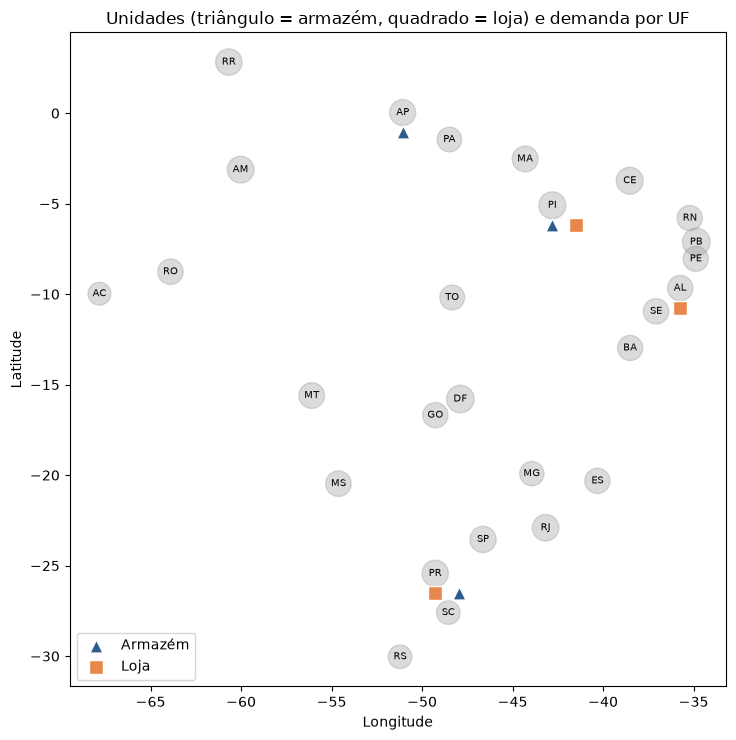

,Unidade,Tipo,UF,Sigla
0,Loja Leão,Loja,Paraná,PR
1,Armazém Camargo,Armazém,Paraná,PR
2,Armazém Siqueira,Armazém,Amapá,AP
3,Armazém Novaes,Armazém,Piauí,PI
4,Loja Oliveira,Loja,Alagoas,AL
5,Loja Mendonça,Loja,Piauí,PI


In [4]:
demanda12 = demanda_por_uf(vendas, DESDE, MES_FIM)
tamanho = 40 + 360 * demanda12["unidades"].reindex(ufs["state"]).to_numpy() / demanda12["unidades"].max()

fig, ax = plt.subplots(figsize=(8, 7.5))
ax.scatter(ufs["longitude"], ufs["latitude"], s=tamanho, color=CORES[4], alpha=0.35, zorder=1)
for _, linha in ufs.iterrows():
    ax.annotate(linha["state"], (linha["longitude"], linha["latitude"]), ha="center", va="center", fontsize=7, zorder=2)

ativos = locais[locais["is_active"].astype(bool)].copy()
ativos["posicao"] = ativos.groupby("state").cumcount()
for tipo, marcador in ((CD, "^"), (PDV, "s")):
    sub = ativos[ativos["location_type"] == tipo]
    ax.scatter(
        sub["longitude"] + 1.3 * sub["posicao"], sub["latitude"] - 1.1, marker=marcador, s=90,
        color=COR_TIPO[tipo], edgecolor="white", zorder=3, label=NOME_TIPO[tipo],
    )
ax.set_aspect("equal")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Unidades (triângulo = armazém, quadrado = loja) e demanda por UF")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

resumo = ativos.assign(UF=ativos["state"].map(NOMES_UF))[["location_name", "location_type", "UF", "state"]]
resumo["location_type"] = resumo["location_type"].map(NOME_TIPO)
display(resumo.rename(columns={"location_name": "Unidade", "location_type": "Tipo", "state": "Sigla"}).reset_index(drop=True))

## 3. A distância que a rede paga hoje

Duas medidas lado a lado, ambas ponderadas por unidades vendidas:

- **distância real**: do cliente até a unidade que de fato atendeu o pedido (par origem → UF do cliente, direto do fato de vendas);
- **distância ideal**: do cliente até a unidade **mais próxima**, que é o que o pedido percorreria se saísse dela.

A venda no PDV (`pos`) e o e-commerce foram separados porque, em teoria, têm geografias diferentes: na loja física o cliente foi até a unidade, então a distância seria pequena. Vale conferir se os dados confirmam isso.

In [5]:
dist = distancia_uf_local(ufs, locais)
atual = distancia_atendimento_atual(dist)

linhas = []
for canal, sub in [("todos", janela), *janela.groupby("channel")]:
    tabela, descartado = distancia_real_de_atendimento(sub, dist)
    ponderada = (tabela["unidades"] * tabela["distancia_media_km"]).sum() / tabela["unidades"].sum()
    linhas.append(
        {
            "Canal": canal,
            "Unidades (12m)": sub["quantity_ordered"].sum(),
            "Distância real (km)": ponderada,
            "% que saiu da unidade mais próxima": participacao_unidade_mais_proxima(sub, dist) * 100,
            "% fora da conta": descartado * 100,
        }
    )
por_canal = pd.DataFrame(linhas).set_index("Canal")

real_uf, _ = distancia_real_de_atendimento(janela, dist)
real_uf = real_uf.set_index("state")
demanda_uf = real_uf["unidades"]
ideal = (demanda_uf * atual.reindex(real_uf.index)).sum() / demanda_uf.sum()
display(por_canal.round(1))
print(f"Distância ideal (despacho pela unidade mais próxima): {br(ideal)} km")
print(f"Distância real: {br(por_canal.loc['todos', 'Distância real (km)'])} km  ->  {por_canal.loc['todos', 'Distância real (km)'] / ideal - 1:+.0%} acima do ideal")

,Unidades (12m),Distância real (km),% que saiu da unidade mais próxima,% fora da conta
Canal,,,,
todos,139423.0,1657.1,26.4,0.0
ecommerce,97913.0,1665.1,26.1,0.0
pos,41510.0,1638.3,27.2,0.0


Distância ideal (despacho pela unidade mais próxima): 636 km
Distância real: 1.657 km  ->  +161% acima do ideal


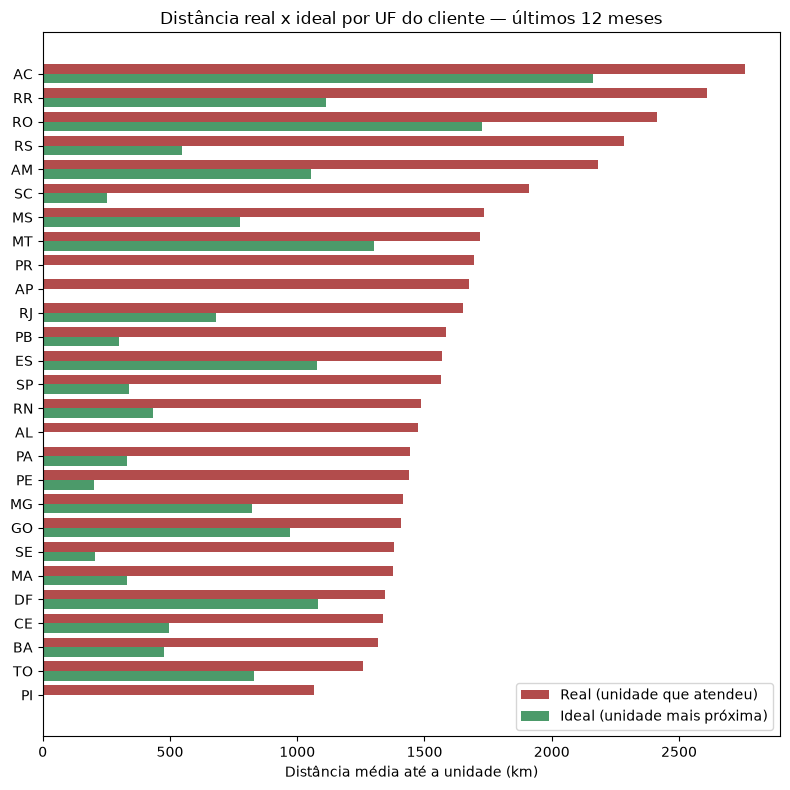

In [6]:
comparacao = pd.DataFrame({"real": real_uf["distancia_media_km"], "ideal": atual.reindex(real_uf.index)}).sort_values("real")
posicao = np.arange(len(comparacao))
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(posicao + 0.2, comparacao["real"], height=0.4, color=CORES[3], label="Real (unidade que atendeu)")
ax.barh(posicao - 0.2, comparacao["ideal"], height=0.4, color=CORES[2], label="Ideal (unidade mais próxima)")
ax.set_yticks(posicao)
ax.set_yticklabels(comparacao.index)
ax.set_xlabel("Distância média até a unidade (km)")
ax.set_title("Distância real x ideal por UF do cliente — últimos 12 meses")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**O que os dados mostram:**

- Cada uma das 6 unidades vende para as 27 UFs em proporções quase iguais. O pedido **não** está sendo despachado pela unidade mais próxima: só cerca de um quarto das unidades sai dela.
- **A separação por canal não muda a história.** A venda no PDV (`pos`) também tem clientes espalhados pelo país, com distância média praticamente igual à do e-commerce. A hipótese de que "loja física = distância zero" não se confirma nestes dados, então o canal não altera a conclusão. A separação foi mantida no módulo por ser a leitura correta em geral.
- A distância real é mais de **2,5 vezes** a ideal. Essa é a folga que existe **antes** de qualquer novo ponto.

## 4. Onde está a demanda e onde ela cresce

O ranking usa quatro sinais por UF: unidades vendidas, receita líquida, distância até a unidade mais próxima e crescimento em 12 meses contra os 12 anteriores. O crescimento vira `NaN` (e não um número inflado) quando a história não cobre os 24 meses de comparação.

,UF,unidades,receita,lucro_estimado,linhas,crescimento_pct,referencia_incompleta,distancia_ao_ponto_mais_proximo_km
state,,,,,,,,
PB,Paraíba,6175.0,10556176.7,4268667.3,1094,22.7,False,299.6
DF,Distrito Federal,6078.0,10591537.2,4359340.2,1119,14.7,False,1081.0
PI,Piauí,5803.0,9643182.8,3941674.6,1054,24.7,False,0.0
CE,Ceará,5783.0,9533048.7,3881274.3,1067,25.3,False,497.4
AM,Amazonas,5700.0,9821195.5,4052637.3,1043,15.4,False,1055.0
RJ,Rio de Janeiro,5612.0,9735949.2,4024949.9,1018,14.3,False,679.3
RR,Roraima,5559.0,9849437.0,4065444.8,1017,14.6,False,1111.9
PR,Paraná,5526.0,9292127.1,3813049.2,1018,20.5,False,0.0
SP,São Paulo,5443.0,9216274.2,3813744.0,1024,7.9,False,339.1


Unidades por UF: mínimo 3.983, máximo 6.175, coeficiente de variação 10%


Correlação de postos (Spearman) entre distância à unidade mais próxima e unidades vendidas: -0.10
Correlação de postos (Spearman) entre distância à unidade mais próxima e crescimento:      -0.37


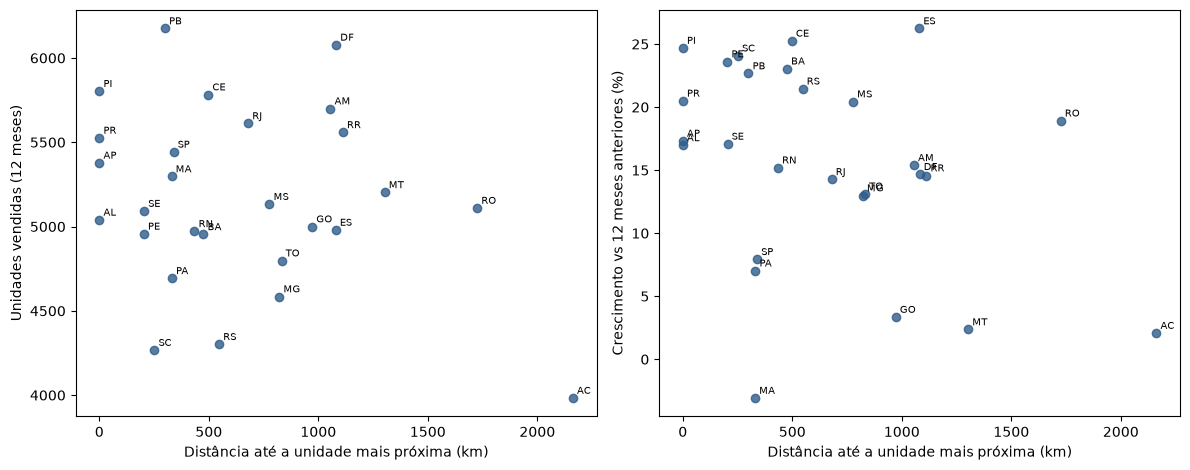

In [7]:
crescimento = crescimento_yoy_por_uf(vendas, MES_FIM)
uf_tabela = demanda12.join(crescimento[["crescimento_pct", "referencia_incompleta"]]).join(atual.rename("distancia_ao_ponto_mais_proximo_km"))
uf_tabela.insert(0, "UF", uf_tabela.index.map(NOMES_UF))
display(uf_tabela.sort_values("unidades", ascending=False).round(1).head(10))

print(f"Unidades por UF: mínimo {br(uf_tabela['unidades'].min())}, máximo {br(uf_tabela['unidades'].max())}, "
      f"coeficiente de variação {uf_tabela['unidades'].std() / uf_tabela['unidades'].mean():.0%}")
print(f"Correlação de postos (Spearman) entre distância à unidade mais próxima e unidades vendidas: "
      f"{uf_tabela['distancia_ao_ponto_mais_proximo_km'].corr(uf_tabela['unidades'], method='spearman'):+.2f}")
print(f"Correlação de postos (Spearman) entre distância à unidade mais próxima e crescimento:      "
      f"{uf_tabela['distancia_ao_ponto_mais_proximo_km'].corr(uf_tabela['crescimento_pct'], method='spearman'):+.2f}")

fig, eixos = plt.subplots(1, 2, figsize=(12, 4.8))
for eixo, coluna, rotulo in (
    (eixos[0], "unidades", "Unidades vendidas (12 meses)"),
    (eixos[1], "crescimento_pct", "Crescimento vs 12 meses anteriores (%)"),
):
    eixo.scatter(uf_tabela["distancia_ao_ponto_mais_proximo_km"], uf_tabela[coluna], color=CORES[0], alpha=0.8)
    for uf, linha in uf_tabela.iterrows():
        eixo.annotate(uf, (linha["distancia_ao_ponto_mais_proximo_km"], linha[coluna]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    eixo.set_xlabel("Distância até a unidade mais próxima (km)")
    eixo.set_ylabel(rotulo)
plt.tight_layout()
plt.show()

**Leitura:**

- A demanda é **muito parecida entre as UFs** (variação de cerca de 10% em torno da média). Por isso o ranking de candidatos é decidido, sobretudo, pela **geografia** — quem está longe de tudo — e não pelo volume de vendas.
- Não há sinal de que as UFs mais distantes vendam menos (correlação próxima de zero). Ou seja, **nestes dados não aparece o viés de "vende pouco porque é mal atendida"**. Isso é ausência de evidência, não prova de que ele não exista: com só 27 UFs e 6 unidades, o teste tem pouco poder.
- Há uma inclinação moderada de as UFs mais distantes **crescerem menos** (correlação negativa, com só 27 pontos). É compatível com atendimento pior freando o crescimento, mas não é conclusivo.

## 5. O que um ponto novo economizaria

Para cada UF candidata, o **ganho** é o quanto a rede deixaria de percorrer se abrisse um ponto ali: cada UF passa a ser atendida pelo mais próximo entre a unidade que já tem e o ponto novo, e o ganho é a soma de *unidades × quilômetros economizados*. Um ponto novo nunca piora a distância, e uma UF que já tem unidade ganha zero. Este é o problema clássico de **localização de instalação** (p-median).

`Km médio evitado` é o ganho dividido pelas unidades totais da rede: quantos quilômetros cada unidade vendida deixaria de percorrer, em média.

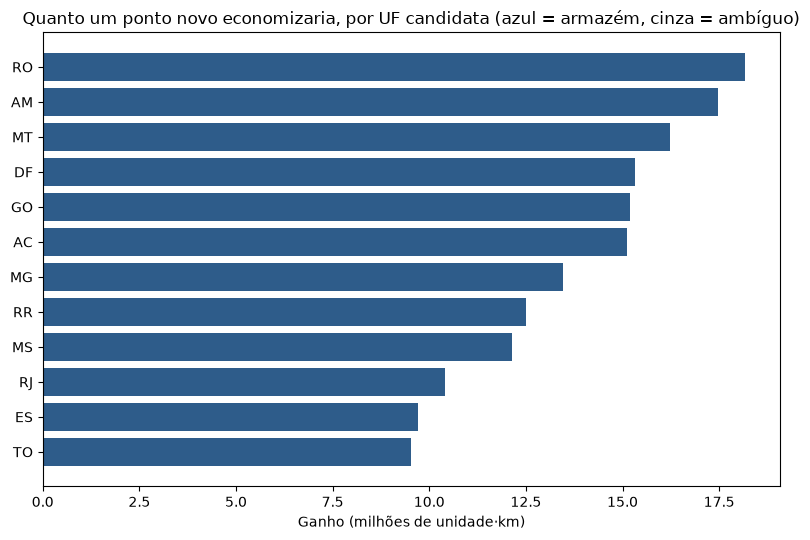

,UF,ganho_unidade_km,km_medio_evitado,ganho_propria_uf,n_ufs_beneficiadas,distancia_atual_km
state,,,,,,
RO,Rondônia,18166045.71,130.29,0.49,4,1725.21
AM,Amazonas,17461300.74,125.24,0.34,4,1054.96
MT,Mato Grosso,16226064.98,116.38,0.42,6,1302.82
DF,Distrito Federal,15326859.19,109.93,0.43,6,1081.01
GO,Goiás,15200352.37,109.02,0.32,8,972.01
AC,Acre,15122098.75,108.46,0.57,2,2162.09
MG,Minas Gerais,13464664.54,96.57,0.28,5,821.76
RR,Roraima,12514872.24,89.76,0.49,4,1111.86


In [8]:
crescimento_serie = crescimento["crescimento_pct"]
ranking = ranquear_candidatos(demanda12, crescimento_serie, ufs, locais)
ranking.insert(0, "UF", ranking.index.map(NOMES_UF))

vistos = ranking.head(12)
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(vistos.index[::-1], vistos["ganho_unidade_km"][::-1] / 1e6, color=[COR_TIPO.get(t, CORES[4]) for t in vistos["tipo_recomendado"][::-1]])
ax.set_xlabel("Ganho (milhões de unidade·km)")
ax.set_title("Quanto um ponto novo economizaria, por UF candidata (azul = armazém, cinza = ambíguo)")
plt.tight_layout()
plt.show()

colunas = ["UF", "ganho_unidade_km", "km_medio_evitado", "ganho_propria_uf", "n_ufs_beneficiadas", "distancia_atual_km"]
display(ranking[colunas].head(8).round(2))

### Um ponto, dois pontos, três pontos

Os candidatos do topo são vizinhos (RO, AM, MT, AC, RR): abrir um deles reduz o valor dos outros. A seleção abaixo abre um ponto por vez, sempre o de maior ganho **dado o que já foi aberto**.

In [9]:
uu = matriz_uf_uf(ufs)
gulosa = selecao_gulosa(demanda12["unidades"], atual, uu, n_pontos=3)
gulosa["UF"] = gulosa["state"].map(NOMES_UF)
print(f"Distância média hoje (com despacho pela unidade mais próxima): {br(ideal)} km")
display(gulosa[["passo", "state", "UF", "ganho_unidade_km", "distancia_media_apos_km"]].round(1))

Distância média hoje (com despacho pela unidade mais próxima): 636 km


,passo,state,UF,ganho_unidade_km,distancia_media_apos_km
0,1,RO,Rondônia,18166045.7,505.4
1,2,DF,Distrito Federal,14473091.1,401.6
2,3,RJ,Rio de Janeiro,7738865.8,346.1


### E se o despacho não mudar?

O ganho acima supõe que o cliente seja atendido pela unidade mais próxima. Como hoje isso acontece em uma minoria dos pedidos, vale testar o outro extremo: **os pedidos continuam sendo repartidos como hoje** e o ponto novo entra como mais uma unidade, recebendo uma fatia igual às demais (1/7).

In [10]:
n_ativas = int(locais["is_active"].sum())
real_por_uf = real_uf["distancia_media_km"]
peso_uf = real_uf["unidades"]
hoje_real = (peso_uf * real_por_uf).sum() / peso_uf.sum()
cenario = []
for candidato in ("RO", "AM", "DF", "RJ"):
    nova = (n_ativas / (n_ativas + 1)) * real_por_uf + (1 / (n_ativas + 1)) * uu[candidato].reindex(real_por_uf.index)
    media = (peso_uf * nova).sum() / peso_uf.sum()
    cenario.append({"Ponto novo": candidato, "Distância média (km)": media, "Variação vs hoje": media / hoje_real - 1})
print(f"Distância real hoje: {br(hoje_real)} km")
display(pd.DataFrame(cenario).round(3))

Distância real hoje: 1.657 km


,Ponto novo,Distância média (km),Variação vs hoje
0,RO,1731.471,0.045
1,AM,1715.844,0.035
2,DF,1607.116,-0.030
3,RJ,1652.497,-0.003


**Leitura:** com o despacho de hoje, um armazém em RO **aumenta** a distância média — o ponto novo recebe uma fatia dos pedidos de UFs que ficam longe dele. Um ponto no DF, mais central, reduz um pouco. **O ponto novo só entrega o ganho da seção anterior se vier junto com despacho por proximidade.**

## 6. O ranking: ganho versus score composto

O **score** combina quatro parcelas, cada uma normalizada de 0 a 1 dentro do conjunto de UFs: unidades (25%), receita líquida (25%), distância até a unidade mais próxima (30% — quanto mais longe, maior a nota) e crescimento (20%). As parcelas ficam à vista na tabela; a nota nunca é uma caixa-preta.

Como os pesos são uma escolha, o teste seguinte sorteia mil combinações de pesos e conta em quantas delas cada UF fica entre as três primeiras.

In [11]:
frequencia = frequencia_no_topo(ranking, top=3, n_sorteios=1000, semente=0)
ranking["freq_top3_score"] = frequencia

colunas = ["UF", "rank_ganho", "rank_score", "score", "parcela_unidades", "parcela_receita", "parcela_distancia", "parcela_crescimento", "freq_top3_score", "baixa_confianca"]
display(ranking.sort_values("rank_score")[colunas].head(10).round(2))

top5_ganho = set(ranking.nsmallest(5, "rank_ganho").index)
top5_score = set(ranking.nsmallest(5, "rank_score").index)
print("Top 5 por ganho :", sorted(top5_ganho))
print("Top 5 por score :", sorted(top5_score))
print("Nos dois        :", sorted(top5_ganho & top5_score))
print()
print("Frequência no top 3 do score (1.000 sorteios de pesos):")
print(frequencia.sort_values(ascending=False).head(8).round(2).to_dict())

,UF,rank_ganho,rank_score,score,parcela_unidades,parcela_receita,parcela_distancia,parcela_crescimento,freq_top3_score,baixa_confianca
state,,,,,,,,,,
DF,Distrito Federal,4,1,0.76,0.96,1.00,0.50,0.61,0.78,False
PB,Paraíba,14,2,0.71,1.00,0.99,0.14,0.88,0.72,False
AM,Amazonas,2,3,0.67,0.78,0.79,0.49,0.63,0.28,False
RO,Rondônia,1,4,0.66,0.51,0.55,0.80,0.75,0.29,False
RR,Roraima,8,5,0.65,0.72,0.80,0.51,0.60,0.10,False
CE,Ceará,18,6,0.65,0.82,0.71,0.23,0.97,0.41,False
RJ,Rio de Janeiro,10,7,0.59,0.74,0.77,0.31,0.59,0.00,False
PI,Piauí,26,8,0.58,0.83,0.74,0.00,0.95,0.18,False
ES,Espírito Santo,11,9,0.58,0.45,0.47,0.50,1.00,0.16,False


Top 5 por ganho : ['AM', 'DF', 'GO', 'MT', 'RO']
Top 5 por score : ['AM', 'DF', 'PB', 'RO', 'RR']
Nos dois        : ['AM', 'DF', 'RO']

Frequência no top 3 do score (1.000 sorteios de pesos):
{'DF': 0.78, 'PB': 0.72, 'CE': 0.41, 'RO': 0.29, 'AM': 0.28, 'PI': 0.18, 'ES': 0.16, 'RR': 0.1}


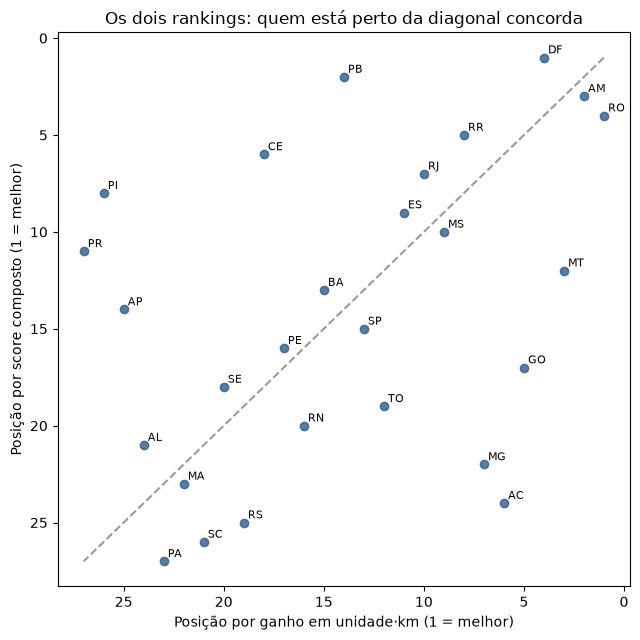

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(ranking["rank_ganho"], ranking["rank_score"], color=CORES[0], alpha=0.8)
for uf, linha in ranking.iterrows():
    ax.annotate(uf, (linha["rank_ganho"], linha["rank_score"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.plot([1, len(ranking)], [1, len(ranking)], color=CORES[4], linestyle="--")
ax.invert_xaxis()
ax.invert_yaxis()
ax.set_xlabel("Posição por ganho em unidade·km (1 = melhor)")
ax.set_ylabel("Posição por score composto (1 = melhor)")
ax.set_title("Os dois rankings: quem está perto da diagonal concorda")
plt.tight_layout()
plt.show()

**Leitura:**

- Os dois rankings **não são idênticos**, e isso é o achado: o ganho em unidade·km privilegia UFs remotas cuja abertura aproxima muita gente ao mesmo tempo (RO, AM, MT); o score, com peso em volume e crescimento, favorece DF e PB.
- **RO, AM e DF aparecem entre os cinco primeiros nos dois.** São os candidatos com sustentação nas duas leituras.
- O DF (78% dos sorteios) e a Paraíba (72%) são os mais **robustos ao peso** do score. A Paraíba, porém, vale pouco como ponto novo (14º no ganho): já está a 300 km de uma unidade e vende bastante. RO e AM ficam no topo do ranking por ganho, mas sua posição no score (29% e 28% dos sorteios no top 3) depende de quanto peso a distância recebe.
- Entre RO e AM a diferença de ganho é de apenas **4%**. Na prática é um empate técnico, e a escolha entre os dois precisa de informação que não está aqui (custo do terreno, capacidade, incentivos fiscais).

## 7. Loja ou armazém?

A regra usa duas perguntas sobre o candidato:

- **Para onde vai o ganho?** Se uma parte relevante dele (mais de 30%) fica **fora** da própria UF, o ponto serve uma região e faz sentido como **armazém**. Se fica concentrada na própria UF (70% ou mais), é presença local, e a resposta é **loja**, desde que já exista armazém a até 300 km.
- **Se o ganho é concentrado e não há armazém por perto**, o caso é **ambíguo**: seria um centro isolado sem demanda regional que o sustente.

O motivo é escrito em texto para cada UF, e os limites são parâmetros — a tabela abaixo mostra que a classificação dos candidatos do topo não depende deles.

In [13]:
display(ranking[["UF", "rank_ganho", "tipo_recomendado", "ganho_propria_uf", "n_ufs_beneficiadas", "motivo"]].head(8).round(2))

sensibilidade = {}
for limite in (0.5, 0.7, 0.9):
    r = ranquear_candidatos(demanda12, crescimento_serie, ufs, locais, limite_concentracao=limite)
    sensibilidade[f"limite {limite:.0%}"] = r["tipo_recomendado"].head(8)
display(pd.DataFrame(sensibilidade))

,UF,rank_ganho,tipo_recomendado,ganho_propria_uf,n_ufs_beneficiadas,motivo
state,,,,,,
RO,Rondônia,1,warehouse,0.49,4,"ganho espalhado: 51% fora da própria UF, 4 UFs..."
AM,Amazonas,2,warehouse,0.34,4,"ganho espalhado: 66% fora da própria UF, 4 UFs..."
MT,Mato Grosso,3,warehouse,0.42,6,"ganho espalhado: 58% fora da própria UF, 6 UFs..."
DF,Distrito Federal,4,warehouse,0.43,6,"ganho espalhado: 57% fora da própria UF, 6 UFs..."
GO,Goiás,5,warehouse,0.32,8,"ganho espalhado: 68% fora da própria UF, 8 UFs..."
AC,Acre,6,warehouse,0.57,2,"ganho espalhado: 43% fora da própria UF, 2 UFs..."
MG,Minas Gerais,7,warehouse,0.28,5,"ganho espalhado: 72% fora da própria UF, 5 UFs..."
RR,Roraima,8,warehouse,0.49,4,"ganho espalhado: 51% fora da própria UF, 4 UFs..."


,limite 50%,limite 70%,limite 90%
state,,,
RO,warehouse,warehouse,warehouse
AM,warehouse,warehouse,warehouse
MT,warehouse,warehouse,warehouse
DF,warehouse,warehouse,warehouse
GO,warehouse,warehouse,warehouse
AC,ambiguo,warehouse,warehouse
MG,warehouse,warehouse,warehouse
RR,warehouse,warehouse,warehouse


**Leitura:** RO, AM, MT, DF, GO e MG saem como **armazém** em qualquer limite testado; só o AC muda de armazém para ambíguo com o limite mais baixo. O motivo é geográfico: os candidatos do Norte e do Centro-Oeste aproximam várias UFs ao mesmo tempo, e a maior parte do ganho fica fora da própria UF. Nenhum candidato sai como loja: onde o ganho é concentrado (CE, RS, MA, PA) o resultado é ambíguo, e o valor total desses candidatos é pequeno.

## 8. Distância é mesmo o problema?

Um ponto novo resolve distância, não capacidade. Antes de concluir, vale conferir se alguma unidade atual tem problema próprio que a distância esconderia. Aqui não há dado de entrega ao cliente (`orders` só registra a data do pedido), então os indicadores vêm do lado de **compras e estoque**:

- **% de recebimentos atrasados**: itens comprados de fornecedores que chegaram depois da data prometida;
- **% de itens em estoque crítico**: itens com estoque zerado ou abaixo do ponto de reposição.

In [14]:
saude = (
    locais[["sk_location", "nk_location_id", "location_name", "location_type", "state"]]
    .merge(recebimento, on="sk_location", how="left")
    .merge(estoque.rename(columns={"location_id": "nk_location_id"}), on="nk_location_id", how="left")
)
saude["location_type"] = saude["location_type"].map(NOME_TIPO)
saude["pct_atrasado"] = saude["pct_atrasado"] * 100
saude["pct_critico"] = saude["pct_critico"] * 100
display(
    saude.drop(columns=["sk_location", "nk_location_id"])
    .rename(columns={"location_name": "Unidade", "location_type": "Tipo", "state": "UF", "pct_atrasado": "% recebimentos atrasados", "pct_critico": "% estoque crítico"})
    .round(1)
)
print(f"% atrasado: {saude['pct_atrasado'].min():.1f}% a {saude['pct_atrasado'].max():.1f}%   |   % crítico: {saude['pct_critico'].min():.1f}% a {saude['pct_critico'].max():.1f}%")

,Unidade,Tipo,UF,itens_recebidos,atraso_medio_dias,% recebimentos atrasados,itens_em_estoque,% estoque crítico
0,Loja Leão,Loja,PR,632,-15.7,15.5,1009,31.8
1,Armazém Camargo,Armazém,PR,691,-18.4,15.8,1009,30.1
2,Armazém Siqueira,Armazém,AP,787,-16.2,17.2,1009,24.7
3,Armazém Novaes,Armazém,PI,708,-17.6,14.4,1009,32.5
4,Loja Oliveira,Loja,AL,728,-14.5,17.6,1009,33.0
5,Loja Mendonça,Loja,PI,729,-18.4,13.0,1009,34.6


% atrasado: 13.0% a 17.6%   |   % crítico: 24.7% a 34.6%


**Leitura:** nenhuma unidade é um ponto fora da curva: os atrasos de recebimento ficam na faixa de 13% a 18% e o estoque crítico entre 25% e 35% em todas. Ou seja, **a distância não está mascarando um problema de capacidade em uma unidade específica**.

Mas o número em si merece atenção: **cerca de um terço dos itens está em estoque crítico em todas as unidades**. Se o despacho por proximidade for adotado, cada unidade precisará ter o estoque certo para os estados que passará a atender — esse é um risco operacional real da recomendação 1.

## 9. O que estes dados não provam

- **Frete real.** O custo logístico aqui é *demanda × km em linha reta*. Rota, modal, pedágio, prazo contratado e tarifa por região não estão no projeto e podem mudar a ordem dos candidatos.
- **Localização.** Clientes e unidades são posicionados na capital da UF. Em estados grandes (AM, PA, MT, MG), a capital pode estar longe da maior parte da demanda. Serve para decidir *entre* UFs, não para escolher a cidade.
- **Investimento.** Não há custo de terreno, obra, folha ou imposto. A análise diz onde o ganho logístico é maior, não se ele paga o investimento.
- **Capacidade e estoque.** O ganho supõe que a unidade nova atenderia toda a demanda que fica mais perto dela. Nada garante que caiba.
- **Demanda que não existe ainda.** UFs mal atendidas podem vender menos por isso. Os dados não mostram esse efeito, mas o teste é fraco; população e renda por UF (dados externos) ajudariam.
- **Poucas unidades.** Com 6 unidades em 4 UFs, quase qualquer ponto novo parece bom. Por isso o notebook mostra o ganho absoluto (km) e não só o ranking, e por isso o resultado é **direcional**: compara UFs entre si, não prevê retorno.

## Conclusão

**Recomendação, em ordem:**

1. **Despachar pela unidade mais próxima antes de construir qualquer coisa.** A rede percorre 1.657 km por unidade vendida contra 636 km possíveis; só 26% das unidades saem da unidade mais próxima. É o maior ganho disponível e não exige investimento em infraestrutura — exige regra de alocação de pedido e estoque compatível (seção 8).
2. **Se for abrir um ponto, um armazém na região Norte — Rondônia (RO) ou Amazonas (AM).** RO maximiza o ganho (cerca de 130 km a menos por unidade vendida, 636 → 505 km); AM fica 4% atrás no ganho e à frente em volume de vendas. É um empate técnico que só se desfaz com dados que este projeto não tem (terreno, capacidade, incentivos).
3. **Segundo ponto: Distrito Federal (DF).** Depois de RO, o DF é o candidato de maior valor (505 → 402 km) e um dos mais robustos ao peso do score. Um terceiro ponto (RJ) leva a média a 346 km, com retorno já bem menor.
4. **Não abrir RO sem mudar o despacho:** com a repartição atual dos pedidos a distância média sobe (1.657 → 1.731 km).

**Onde a conclusão é frágil:** o ranking depende de a capital representar a UF e de o frete ser proporcional à distância em linha reta; RO e AM estão empatados; e os dois rankings (ganho e score) só concordam em três UFs — RO, AM e DF.

**Próximos passos naturais:** trazer frete e prazo reais para trocar *km* por custo e dias; incluir população e renda por UF para testar demanda reprimida; e, escolhida a UF, descer para o nível de cidade com coordenadas reais de clientes.

## Apêndice — método

**Entrada.** `agg_sales_by_customer_state_month` (mês × UF do cliente × unidade de origem × canal; sem pedidos cancelados nem rascunhos), `int_uf_coordinates` (capital das 27 UFs, do seed `geo_uf_capital_coordinates`) e `int_location_coordinates` (unidades com a coordenada da capital da própria UF).

**Distância.** Fórmula de haversine (círculo máximo, raio médio da Terra de 6.371 km) entre capitais. É a distância em linha reta, sempre menor ou igual à rodoviária.

**Ganho de um candidato *u*.** Seja *d_v* a demanda da UF *v* (unidades, 12 meses), *a_v* a distância atual de *v* à unidade mais próxima e *D(v, u)* a distância entre *v* e *u*:

```
ganho(u) = soma_v  d_v × max(0, a_v − D(v, u))
```

Nunca é negativo; UF que já tem unidade ganha zero. `km_medio_evitado = ganho / soma(d_v)`. `ganho_propria_uf` é a fração do ganho que vem da própria UF *u*.

**Seleção gulosa.** Abre o candidato de maior ganho, atualiza *a_v* = min(*a_v*, *D(v, u)*) e repete. Não garante o ótimo conjunto (o problema exato é NP-difícil), mas com 27 candidatos é uma boa aproximação e mostra o efeito de redundância entre vizinhos.

**Score composto.** Parcelas min–max (0 a 1): unidades, receita líquida, distância à unidade mais próxima e crescimento (12 meses vs 12 anteriores). Pesos padrão 25/25/30/20. Crescimento ausente entra com parcela zero e a coluna `crescimento_indisponivel` fica marcada. A robustez a pesos usa 1.000 sorteios de uma Dirichlet uniforme, com semente fixa.

**Tipo.** Ganho concentrado (`ganho_propria_uf` ≥ 70%) com armazém a até 300 km → loja; ganho espalhado (< 70%) → armazém; concentrado e longe de armazém → ambíguo; ganho zero → sem ganho.

**Cenário sem mudar o despacho.** A distância esperada de cada UF passa a ser `(n/(n+1)) × real + (1/(n+1)) × D(v, u)`, com *n* = unidades ativas. Supõe que o ponto novo recebe uma fatia igual às demais.

**Código.** `src/analytics_ai/network_expansion.py` (pandas puro, sem Spark) e `tests/test_network_expansion.py`. Modelos dbt: `src/dbt/models/intermediate/int_uf_coordinates.sql`, `int_location_coordinates.sql` e `src/dbt/models/marts/agg_sales_by_customer_state_month.sql`.